# Lab 6: Graphical Models

Welcome to the advanced Machine Learning Course.

The objective of this lab session is to code your own Graphical Lasso and Nodewise regression.

Please put **"ML - MDS - TD6"** in the mail subject or I might lose your work (which means 0) and send it to ludovic.trautmann@inria.fr

Please label your notebook **"L6_familyname1_familyname2.ipynb"**.

Make sure to put comments in your code. **Raw numerical results or plots without comments will have almost no value in the grading. Please make sure to comment yout results.**

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_context('poster')
sns.set_color_codes()
plot_kwds = {'alpha' : 0.25, 's' : 80, 'linewidths':0}
from tqdm import tqdm
import networkx as nx

# Graphical Lasso

Implement your own Graphical Lasso

In [30]:
class my_GLasso():
    
    def __init__(self, lambd=0.01, rho=1.0, max_iter=200, tol=1e-3):
        '''
        Graphical Lasso solved with ADMM.

        Parameters:
        lambd : float
            Penalization parameter (applied to the off-diagonal entries only).
        rho: float>0
            ADMM augmented Lagrangian parameter.
        max_iter : int
            Maximum number of iterations.
        tol : float
            Stopping tolerance on the primal and dual residuals.

        Attributes:
        
        covariance_ : numpy.ndarray, shape (n_features, n_features)
            Estimated covariance matrix.
        precision_ : numpy.ndarray, shape (n_features, n_features)
            Estimated (sparse) precision matrix (inverse covariance).
        '''
        self.covariance_ = None
        self.precision_ = None
        self.lambd = lambd
        self.rho = rho
        self.max_iter = max_iter
        self.tol = tol
        
    def fit(self, X):
        """ Fits the GraphicalLasso model to X.
        
        Parameters:
        -----------
        X: (n, p) np.array
            Data matrix
        
        Returns:
        -----
        self
        """         
        X = X - X.mean(axis=0)  # center the data
        n, p = X.shape
        S = (X.T @ X)/n
        Z = np.identity(p)
        U = np.zeros((p, p))
        offdiag = ~np.eye(p, dtype=bool)
        
        for _ in range(self.max_iter):
            # Theta-update: closed form through an eigendecomposition
            A = self.rho * (Z - U) - S
            eigenvalues, Q = np.linalg.eigh(A)
            new_eigenvalues = (eigenvalues + np.sqrt(eigenvalues**2 + 4*self.rho))/(2*self.rho)
            Theta = (Q * new_eigenvalues) @ Q.T
            
            # Z-update: soft-thresholding, the diagonal is not penalized
            Z_old = Z
            V = Theta + U
            Z = np.where(offdiag, np.sign(V)*np.maximum(np.abs(V) - self.lambd/self.rho, 0), V)
            
            # dual update
            U = U + Theta - Z
            
            # stopping criterion on primal / dual residuals
            r = np.linalg.norm(Theta - Z)
            s = self.rho * np.linalg.norm(Z - Z_old)
            if r < self.tol * p and s < self.tol * p:
                break
        
        # Z is exactly sparse, we use it as the estimator
        self.precision_ = Z
        self.covariance_ = np.linalg.inv(Z)
        return self

vmax=np.float64(2.5661204976696177)


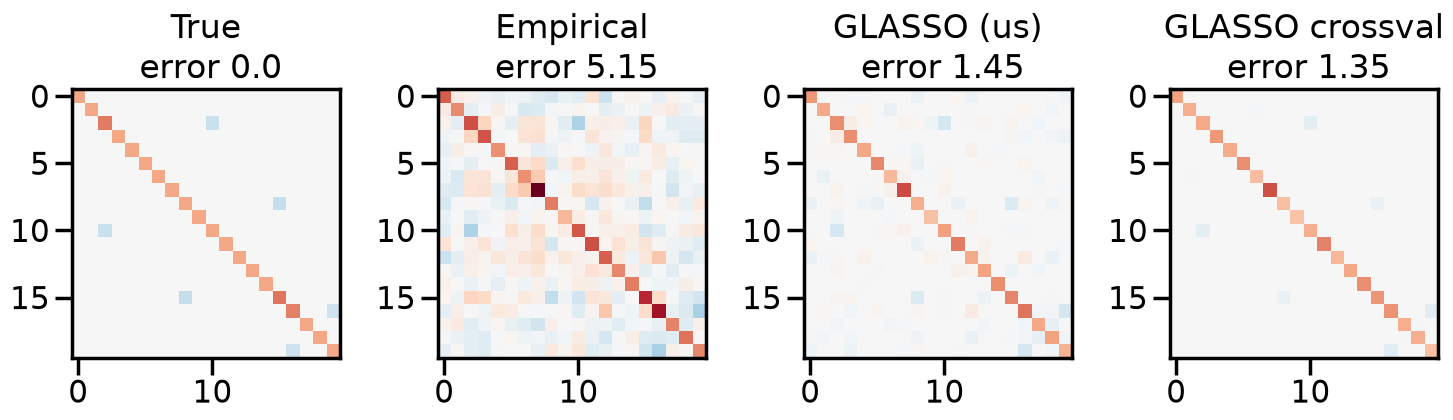

In [31]:
#Compare methods of estimating the covariance matrix in low-sample regime
n_samples = 60
n_features = 20

# Simulate data (multivariate gaussian)
from sklearn.datasets import make_sparse_spd_matrix
rng = np.random.RandomState(1)
prec = make_sparse_spd_matrix(n_features, alpha=.98, smallest_coef=.4, largest_coef=.7, random_state=rng)
cov = np.linalg.inv(prec)
mean = np.zeros(n_features)
data = rng.multivariate_normal(mean, cov, n_samples)
err = 0.  # error of the true precision matrix w.r.t. itself

prec_empirical = np.linalg.inv(np.dot(data.T, data) / n_samples)
err_empirical = np.linalg.norm(prec - prec_empirical)

# Scikit-learn Graphical Lasso with cross validation
from sklearn.covariance import GraphicalLassoCV
prec_glassocv = GraphicalLassoCV().fit(data).precision_
err_glassocv = np.linalg.norm(prec - prec_glassocv)

# Graphical Lasso estimation using our implementation
prec_glasso = my_GLasso(lambd=0.1).fit(data).precision_
err_glasso = np.linalg.norm(prec - prec_glasso)

# Visual comparison
titles = ["True", "Empirical", "GLASSO (us)", "GLASSO crossval"]
imgs = [prec, prec_empirical, prec_glasso, prec_glassocv]
errors = [err, err_empirical, err_glasso, err_glassocv]
vmax = np.max([np.max(prec), np.max(prec_empirical), np.max(prec_glasso), np.max(prec_glassocv)])
print(f"{vmax=}")

ncols = len(titles)
fig, axes = plt.subplots(1, ncols, figsize=(15, 5))
for idx, ax in enumerate(axes.flatten()):
    img = imgs[idx]
    error = np.around(errors[idx], decimals=2)
    title = titles[idx] + f'\n error {error}'
    ax.imshow(img, vmin=-vmax, vmax=vmax, interpolation='nearest', cmap=plt.cm.RdBu_r)
    ax.set_title(title)
fig.tight_layout()

**Remark:** our GLasso uses a fixed $\lambda=0.1$ here, while the scikit-learn version selects it by cross-validation. The errors are therefore not directly comparable; the cross-validated version for our own implementation is in the simulation section. The 2 GLasso estimators recover the structure of the matrix, while the empirical one fails totally.

# Nodewise Regression

Fill in the following class that implements the nodewise regression algorithm to estimate a graphical model structure. You can use `LassoCV` for the regressions.

In [32]:
from sklearn.linear_model import LassoCV

class my_nodewise_regression():
    
    def __init__(self, rule='AND', eps=1e-8):
        '''
        Parameters:
        
        rule: {"OR", "AND"}
        eps: Threshold for checking if beta_ij = 0
        
        Attributes:
        
        graph_structure_ : numpy.ndarray, shape (n_features, n_features)
            Estimated adjacancy matrix.        
        '''
        self.graph_structure_ = None
        self.S_ = None
        self.rule = rule
        self.eps = eps
        
    def fit(self, X):
        """ Fit the model to X.
        
        Parameters:
        -----------
        X: (n, p) np.array
            Data matrix
        
        Returns:
        -----
        Update self.graph_structure_
        """         
        #TODO
        n, p = X.shape
        self.graph_structure_ = np.zeros((p, p))
        S = []
        
        for j in range(p) :
            D_ = np.delete(X, j, axis=1)
            d = X[:, j]
            beta = LassoCV(cv=5,max_iter=10000,tol=1e-4).fit(D_, d).coef_
            S.append([i for i in range(p) if i!= j and np.abs(beta[i if i < j else i-1]) > self.eps])
        
        self.S_ = S
        return self.graph(self.rule)
    
    def graph(self, rule):
        """Build the adjacency matrix from the neighbourhoods S_ with the given rule."""
        p = len(self.S_)
        G = np.zeros((p, p))
        for j in range(p):
            for k in self.S_[j]:
                if rule == "OR" or j in self.S_[k]:
                    G[j, k] = 1
        if rule == "OR":
            G = np.maximum(G, G.T)
        self.graph_structure_ = G
        return G

## Plots

In [33]:
np.random.seed(1)
n = 5000
p = 6
epsilon=1e-1
X = np.random.randn(n, p)
X.T[1] += X.T[0]
X.T[2] += X.T[1]
real_graph_structure = np.zeros((p, p))
real_graph_structure[0,1] = 1
real_graph_structure[1,0] = 1
real_graph_structure[1,2] = 1
real_graph_structure[2,1] = 1

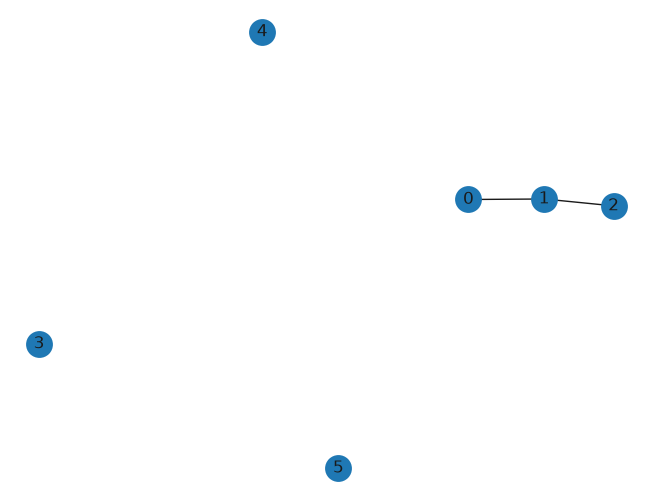

In [34]:
nx_real = nx.from_numpy_array(real_graph_structure.T)
#We draw the initial structure
nx.draw(nx_real, with_labels=True)

We notice that the initial graph is **poorly connected**, there are a lot of conditional independances between the components.

When we will reconstruct the graph with the predicted value of the precision matrix, **we expect higher values for the conditional correlation between nodes 0, 1 and 2**. 

However, based on what we saw before, we must expect a complete graph if we dont specify a minimum weight for the edges to be taken into account.

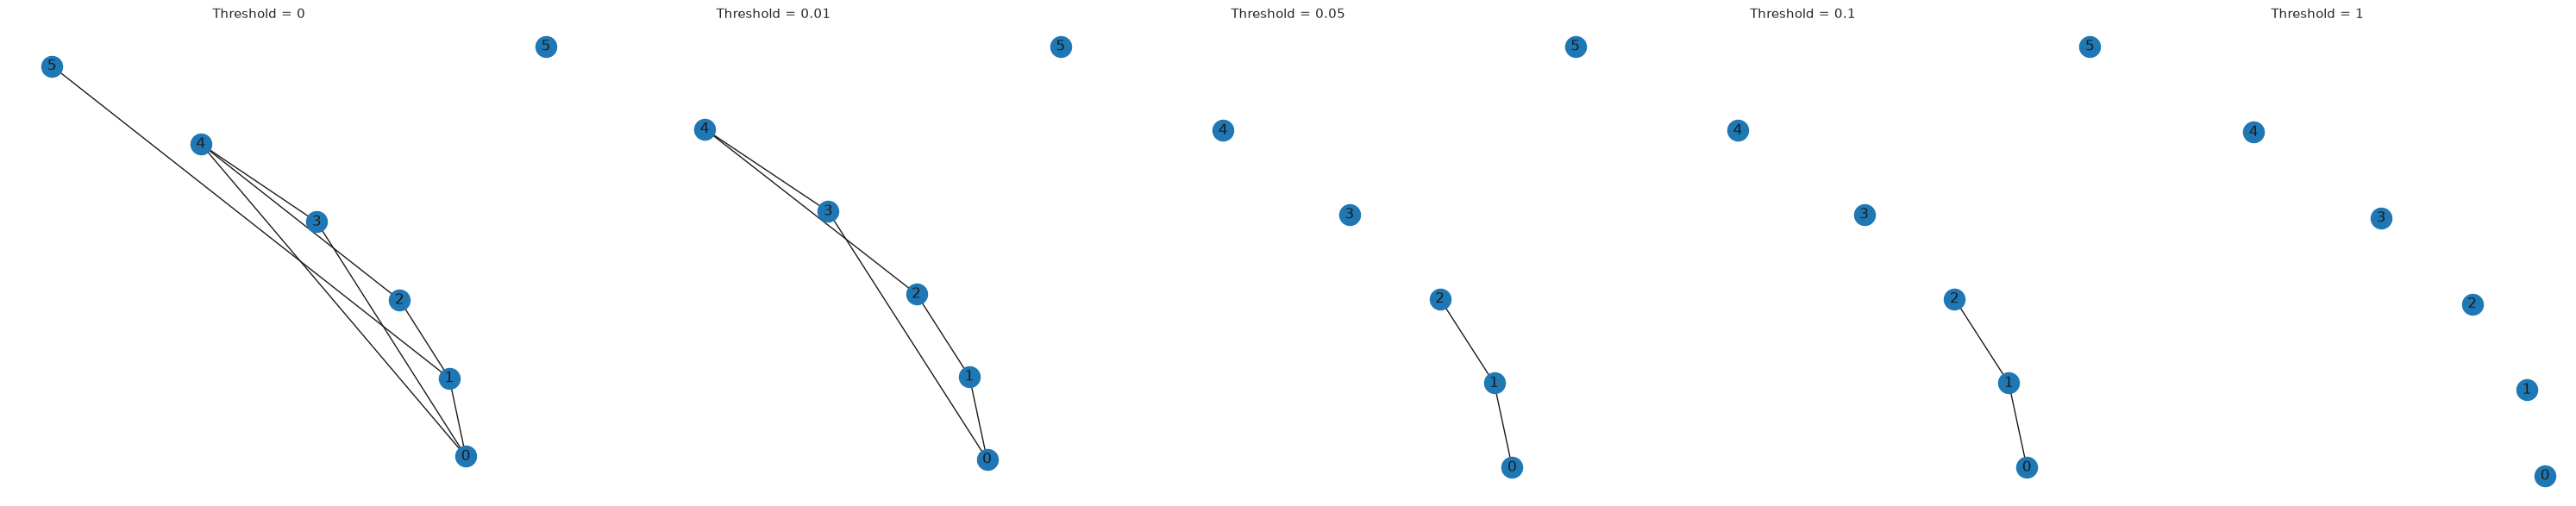

In [56]:
#TODO : plot the reconstructed graph with GLASSO using different thresholds. Comment the impact of the choice of the threshold

model = GraphicalLassoCV()
model.fit(X)

precision = model.precision_


thresholds = [0, 0.01, 0.05, 0.1, 1]


plt.figure(figsize=(6*len(thresholds), 6))
pos = nx.circular_layout(nx.empty_graph(p))
for k, threshold in enumerate(thresholds):
    adjacency = (np.abs(precision) > threshold).astype(int)
    np.fill_diagonal(adjacency, 0)
    G = nx.from_numpy_array(adjacency)

    plt.subplot(1, len(thresholds), k+1)
    nx.draw(G, pos=pos, with_labels=True)
    plt.title(f"Threshold = {threshold}")
plt.tight_layout()
plt.show()


Thresholds are: 0, 0.01, 0.05, 0.1, 1.

**Comments:** With the 0 threshold, the graph contains every non-zero entry of the estimated precision matrix (it is complete unless GLasso set some entries exactly to 0). With the 0.01 threshold, points 0,1,2,3,4 are connected, but not point 5. Above threshold 0.05, points 0, 1 and 2 are connected and points 3, 4 and 5 are left alone. The higher the threshold, the sparser the graph. When we reach 1, as expected, no points are connected at all.

## Plots nodewise regression

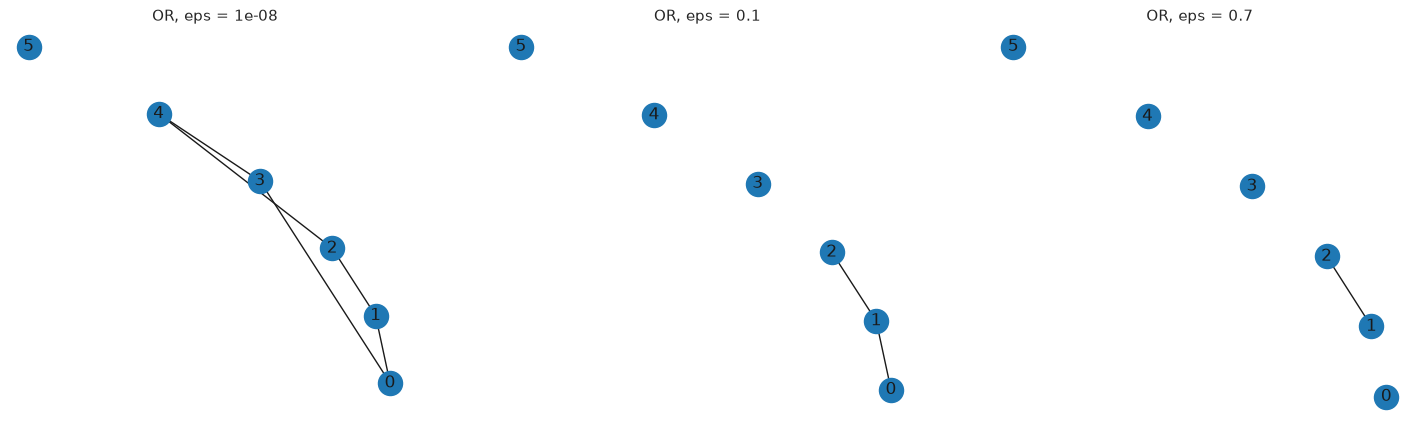

In [57]:
#TODO : plot the reconstructed graph with nodewise regression using the rule OR
# eps is the threshold under which a coefficient beta_ij is considered null, we compare several values
eps_values = [1e-8, 0.1, 0.7]

plt.figure(figsize=(18, 5))
pos = nx.circular_layout(nx.empty_graph(p))
for k, eps in enumerate(eps_values):
    or_graph_structure = my_nodewise_regression(rule = "OR", eps = eps).fit(X)

    nx_real = nx.from_numpy_array(or_graph_structure.T)
    plt.subplot(1, len(eps_values), k+1)
    nx.draw(nx_real, pos=pos, with_labels=True)
    plt.title(f"OR, eps = {eps}")
plt.show()


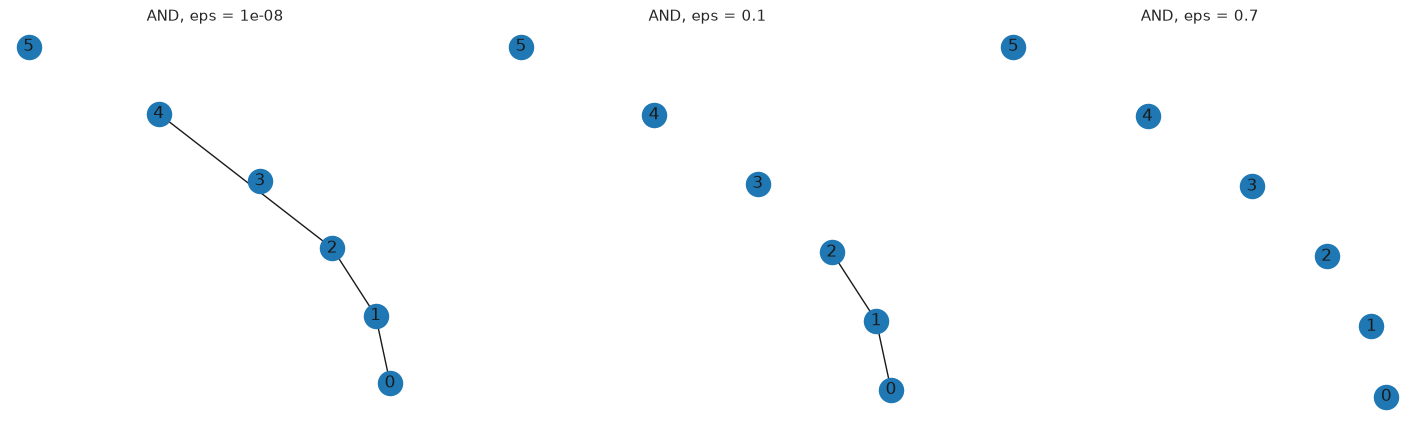

In [58]:
#TODO : plot the reconstructed graph with nodewise regression using the rule AND
# eps is the threshold under which a coefficient beta_ij is considered null, we compare several values
eps_values = [1e-8, 0.1, 0.7]

plt.figure(figsize=(18, 5))
pos = nx.circular_layout(nx.empty_graph(p))
for k, eps in enumerate(eps_values):
    and_graph_structure = my_nodewise_regression(rule = "AND", eps = eps).fit(X)

    nx_real = nx.from_numpy_array(and_graph_structure.T)
    plt.subplot(1, len(eps_values), k+1)
    nx.draw(nx_real, pos=pos, with_labels=True)
    plt.title(f"AND, eps = {eps}")
plt.show()


**Comments:** As expected, the OR graph has more connections than the AND graph, as its less destructive.

# Simulations

Compare the two graph estimators for each of the following models with $p = 300$ and $n = 40, 80, 320$:

- An AR(1)-Block model. In this model the *covariance* matrix is block-diagonal with equalsized AR(1)-blocks of the form $(\Sigma_{Block})_{i, j} = 0.9^{|i−j|}$, take $30 \times 30$ blocks.
- The exponential decay model considered in Fan et al. [2009]. In this model we consider a case where no element of the concentration matrix is exactly zero. The elements of $\Theta$ are given by $\Theta_{ij} = \exp{(−2|i − j|)}$ equals essentially zero when the difference |i − j| is large.

For GLasso estimation, use cross-validation k-fold with loglikelihood loss to select the $\lambda$ penalization parameter. Evaluate your estimation using the Frobenius matrix norm. 

For Node-regression estimation, compare your edge-estimation with the binary (thresholded) covariance matrix. Evaluate your estimation using accuracy and the F1 score. 

In [ ]:
#TODO

from sklearn.linear_model import Lasso

p = 300
n_values = [40, 80, 320]

Sigma_block = np.zeros((p, p))
for b in range(10): 
    idx = np.arange(b * 30, (b + 1) * 30)
    for i in idx:
        for j in idx:
            Sigma_block[i, j] = 0.9 ** abs(i - j) 

Theta_block = np.linalg.inv(Sigma_block)



i, j = np.indices((p, p))
Theta_exp = np.exp(-2 * np.abs(i - j))
Sigma_exp = np.linalg.inv(Theta_exp)

In [39]:
def frobenius_error(Theta_hat, Theta_true):
    return np.linalg.norm(Theta_hat - Theta_true, ord="fro")


def adjacency(Theta, tol=1e-8):
    A = (np.abs(Theta) > tol).astype(int)
    np.fill_diagonal(A, 0)
    return A


def accuracy_score(A_hat, A_true):
    idx = np.triu_indices_from(A_true, k=1)
    return np.mean(A_hat[idx] == A_true[idx])


def f1_score(A_hat, A_true):
    idx = np.triu_indices_from(A_true, k=1)

    y_true = A_true[idx]
    y_pred = A_hat[idx]

    TP = np.sum((y_true == 1) & (y_pred == 1))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))

    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0

    return (2 * precision * recall / (precision + recall)
            if precision + recall > 0 else 0)

In [ ]:
from sklearn.model_selection import KFold

def glasso_cv(X, lambda_grid, K=3):

    kf = KFold(n_splits=K, shuffle=True, random_state=123)

    cv_scores = []

    for lam in tqdm(lambda_grid):

        scores = []

        for train_idx, test_idx in kf.split(X):

            X_train = X[train_idx]
            X_test = X[test_idx]

            model = my_GLasso(lambd=lam)
            Theta_hat = model.fit(X_train).precision_

            # Covariance matrix on validation data
            S_test = np.cov(X_test, rowvar=False)

            # Log-likelihood 
            sign, logdet = np.linalg.slogdet(Theta_hat)

            if sign <= 0:
                scores.append(-np.inf)
                continue

            score = 0.5 * (
                logdet - np.sum(S_test * Theta_hat)
            )

            scores.append(score)

        cv_scores.append(np.mean(scores))

    # Select best lambda
    best_lambda = lambda_grid[np.argmax(cv_scores)]

    # Fit final model on the whole dataset
    final_model = my_GLasso(lambd=best_lambda)
    Theta_hat = final_model.fit(X).precision_

    return Theta_hat, best_lambda

In [ ]:
import pandas as pd

def simulate_model(Sigma, Theta, model_name, n, rep=0):

    A_true = adjacency(Theta, tol=0.05)

    results = []

    lambda_grid = np.logspace(-2, 0, 6)
    
    # Generate data
    X = np.random.multivariate_normal(
        mean=np.zeros(p),
        cov=Sigma,
        size=n
    )

    # GLasso
    Theta_glasso, best_lambda = glasso_cv(
        X, lambda_grid
    )
    error = frobenius_error(
        Theta_glasso, Theta
    )

    # Nodewise Regression
    model_nodewise = my_nodewise_regression(rule="OR", eps=0.01)
    model_nodewise.fit(X)
    for rule in ["OR", "AND"]:
        A_nodewise = model_nodewise.graph(rule)

        # Evaluation
        acc = accuracy_score(A_nodewise, A_true)
        f1 = f1_score(A_nodewise, A_true)

        results.append({
            "Model": model_name,
            "n": n,
            "rep": rep,
            "Rule": rule,
            "Lambda": best_lambda,
            "Frobenius": error,
            "Accuracy": acc,
            "F1": f1
        })

    return pd.DataFrame(results)

In [42]:
np.random.seed(123)

n_rep = 5  # number of repetitions per setting (needed for mean / std)
results = []

for n in n_values:
    for r in range(n_rep):

        print(f"Running n = {n}, rep = {r}")

        results.append(simulate_model(Sigma_block, Theta_block, "AR1-Block", n, r))
        results.append(simulate_model(Sigma_exp, Theta_exp, "Exponential-Decay", n, r))

results = pd.concat(results, ignore_index=True)

Running n = 40, rep = 0


100%|██████████| 6/6 [01:06<00:00, 11.11s/it]


Running n = 40, rep = 1


100%|██████████| 6/6 [00:25<00:00,  4.19s/it]


Running n = 40, rep = 2


100%|██████████| 6/6 [00:27<00:00,  4.52s/it]


... (20 outputs left out)

Running n = 320, rep = 3


100%|██████████| 6/6 [00:12<00:00,  2.05s/it]


Running n = 320, rep = 4


100%|██████████| 6/6 [00:32<00:00,  5.33s/it]


In [ ]:
print(results[results["Rule"] == "OR"].groupby(["Model", "n"])["Frobenius"].agg(["mean", "std"]))

print(results.groupby(["Model", "Rule", "n"]).agg({
    "Accuracy": ["mean", "std"],
    "F1": ["mean", "std"]
}))

                             mean       std
Model             n                        
AR1-Block         40   142.125352  0.133225
                  80   109.130510  0.493351
                  320   84.990048  0.292536
Exponential-Decay 40     5.499552  0.315392
                  80     4.320309  0.018448
                  320    3.593071  0.060482
                            Accuracy                  F1          
                                mean       std      mean       std
Model             Rule n                                          
AR1-Block         AND  40   0.996767  0.000117  0.799265  0.005412
                       80   0.997886  0.000258  0.859716  0.014726
                       320  0.998800  0.000110  0.915160  0.007146
                  OR   40   0.958707  0.001958  0.238478  0.008366
                       80   0.969583  0.001401  0.298572  0.009642
                       320  0.985663  0.001234  0.475027  0.021653
Exponential-Decay AND  40   0.989735  0.00083

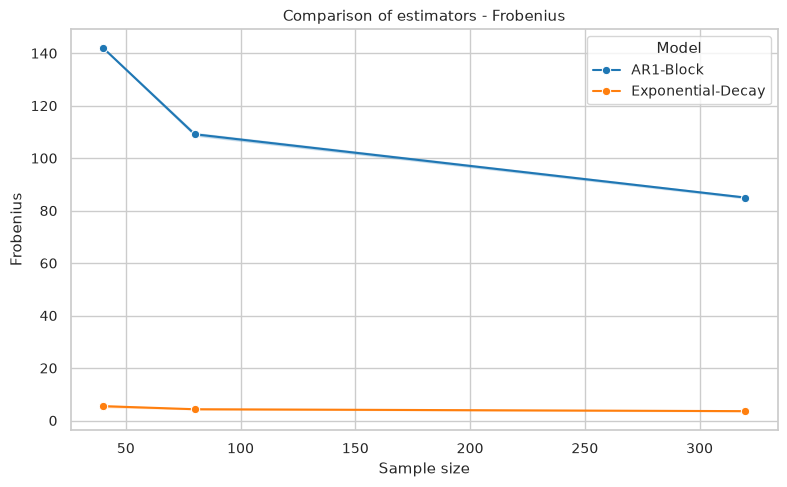

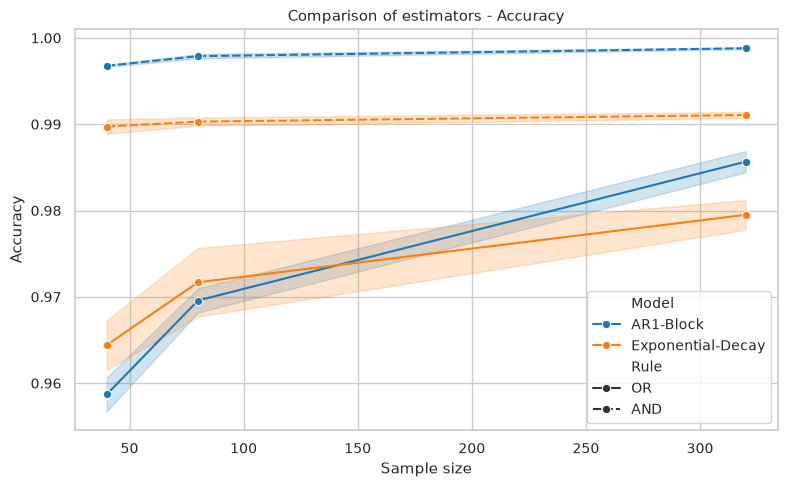

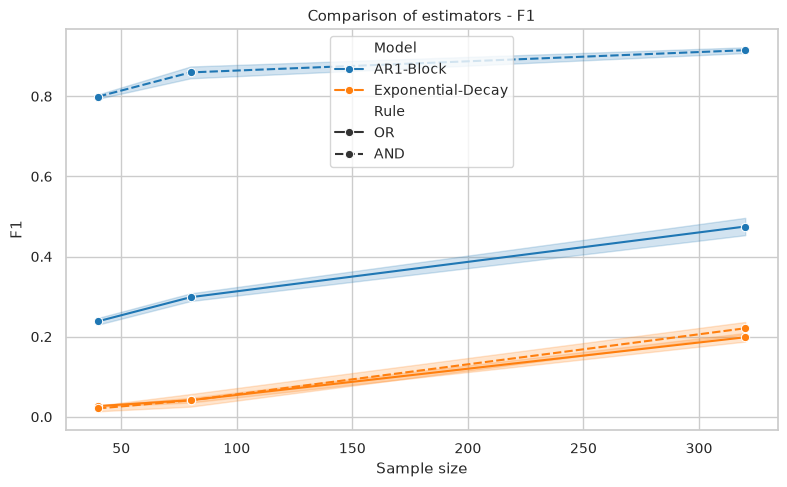

In [47]:
import seaborn as sns

sns.set_style("whitegrid")
sns.set_context("notebook", font_scale=0.9)

metrics = ["Frobenius", "Accuracy", "F1"]

for metric in metrics:

    plt.figure(figsize=(8, 5))

    # Frobenius error only depends on GLasso (same value for both rules)
    if metric == "Frobenius":
        data, style = results[results["Rule"] == "OR"], None
    else:
        data, style = results, "Rule"

    sns.lineplot(
        data=data,
        x="n",
        y=metric,
        hue="Model",
        style=style,
        marker="o",
        errorbar="sd"
    )

    plt.title(f"Comparison of estimators - {metric}")
    plt.xlabel("Sample size")
    plt.ylabel(metric)

    plt.tight_layout()
    plt.show()

**Comments:** With Glasso, the frobenius norm decreases when the number of samples increases with the AR1-Block model. For the exponential decay model, the norm is almost constant. 

With the node regression, the accuracy increases with the number of samples with both models. It is the same for the F1-score. We notice the difference between the AND and the OR rule:  OR adds false positives so as expected the accuracy and F1 of the AND fitting is always better than the OR one. This stays close on exponential decay. The accuracy looks good because most pairs have no connection so the model has nothing to learn; accuracy is good to follow here.